---
title: Comércio varejista ampliado do Ceará
subtitle: Análise mensal e previsão com SARIMA · PMC/IBGE
date: '2026-10-28'
date-format: DD/MM/YYYY
jupyter: python3
output-file: index.html
lang: pt-BR
format:
  html:
    theme: cosmo
    toc: true
    toc-depth: 2
    number-sections: true
    embed-resources: true
    code-fold: true
    code-summary: Mostrar código
    code-tools: true
    css: styles.css
    html-math-method: katex
execute:
  echo: true
  warning: false
  error: false
  cache: false
---

## Objetivo e recorte

Este trabalho analisa o índice de volume de vendas do comércio varejista ampliado do Ceará e projeta os 24 meses seguintes ao último registro da base do exercício. O índice tem referência **2022 = 100** e não possui ajuste sazonal. Seu nível expressa volume relativo de vendas, e não faturamento em reais ou crescimento percentual.

Utiliza-se o arquivo disponibilizado no template da disciplina, atribuído à Pesquisa Mensal de Comércio (PMC) do IBGE. O varejo ampliado abrange, entre outras atividades, veículos e material de construção. A análise preserva a série fornecida pelo professor, sem substituí-la por uma extração mais recente.

::: {.callout-note title="Data de corte"}
A amostra vai de **janeiro de 2004 a fevereiro de 2026**. Assim, o horizonte solicitado corresponde a **março de 2026 a fevereiro de 2028**. Embora o relatório tenha sido elaborado em outubro de 2026, nenhum dado posterior ao corte foi utilizado. As previsões representam o que seria projetado a partir de fevereiro de 2026.
:::

## Ambiente e preparação dos dados

O ambiente é gerenciado por `uv`, com dependências registradas em `pyproject.toml` e versões resolvidas em `uv.lock`. A pasta `.venv` está excluída pelo `.gitignore`. A cópia local da base permite reproduzir os resultados mesmo que o arquivo remoto seja atualizado.

In [1]:
#| label: setup
from pathlib import Path
import hashlib
import json
import math
import platform
import warnings
from importlib.metadata import version
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import jarque_bera
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsforecast.models import AutoARIMA
from statsforecast.arima import ndiffs, nsdiffs

MINHA_UF = "Ceará"
HORIZONTE = 24
FONTE = "https://github.com/padsInsper/202634-fa/releases/download/data/pmc_volume_uf.csv"
PASTA = Path("resultados")
PASTA.mkdir(exist_ok=True)
Path("data").mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 140, "savefig.dpi": 170,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18,
    "axes.titlesize": 12, "font.size": 10,
    "axes.prop_cycle": plt.cycler(color=["#254e70", "#d57a28", "#438776"]),
})

def br(valor, casas=2):
    return f"{float(valor):,.{casas}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def mes(data):
    return pd.Timestamp(data).strftime("%m/%Y")

def tabela(quadro, casas=3):
    display(Markdown(quadro.to_markdown(index=False, floatfmt=f".{casas}f")))

def figura(fig, nome):
    fig.tight_layout()
    fig.savefig(PASTA / nome, bbox_inches="tight", facecolor="white")
    display(fig)
    plt.close(fig)

arquivo = Path("data/pmc_volume_uf.csv")
if not arquivo.exists():
    urlretrieve(FONTE, arquivo)
sha256 = hashlib.sha256(arquivo.read_bytes()).hexdigest()
pmc = pd.read_csv(arquivo, parse_dates=["data"])
assert {"uf", "data", "volume_idx"}.issubset(pmc.columns)
df_sf = (
    pmc.loc[pmc["uf"].eq(MINHA_UF), ["uf", "data", "volume_idx"]]
    .rename(columns={"uf": "unique_id", "data": "ds", "volume_idx": "y"})
    .sort_values("ds").reset_index(drop=True)
)
assert not df_sf.empty, "UF não encontrada na base."
assert not df_sf["ds"].duplicated().any(), "Há meses duplicados."
df_sf["y"] = pd.to_numeric(df_sf["y"], errors="raise")
assert np.isfinite(df_sf["y"]).all() and df_sf["y"].gt(0).all()
esperado = pd.date_range(df_sf["ds"].min(), df_sf["ds"].max(), freq="MS")
assert df_sf["ds"].tolist() == esperado.tolist(), "Há lacunas no calendário mensal."
y = df_sf.set_index("ds")["y"].asfreq("MS")
assert abs(y.loc["2022"].mean() - 100) < 0.01
df_sf.to_csv("data/pmc_ceara.csv", index=False)

tabela(pd.DataFrame({
    "Verificação": ["UF", "Início", "Fim", "Observações", "Meses faltantes",
                    "Duplicações", "Média de 2022"],
    "Resultado": [MINHA_UF, mes(y.index.min()), mes(y.index.max()), len(y),
                  0, 0, br(y.loc["2022"].mean())],
}))

| Verificação     | Resultado   |
|:----------------|:------------|
| UF              | Ceará       |
| Início          | 01/2004     |
| Fim             | 02/2026     |
| Observações     | 266         |
| Meses faltantes | 0           |
| Duplicações     | 0           |
| Média de 2022   | 100,00      |

## Análise descritiva

### Evolução, tendência e sazonalidade

| Estatística   |   Índice (2022 = 100) |
|:--------------|----------------------:|
| Média         |                89.675 |
| Mediana       |                94.322 |
| Desvio-padrão |                23.018 |
| Mínimo        |                34.605 |
| Máximo        |               134.892 |

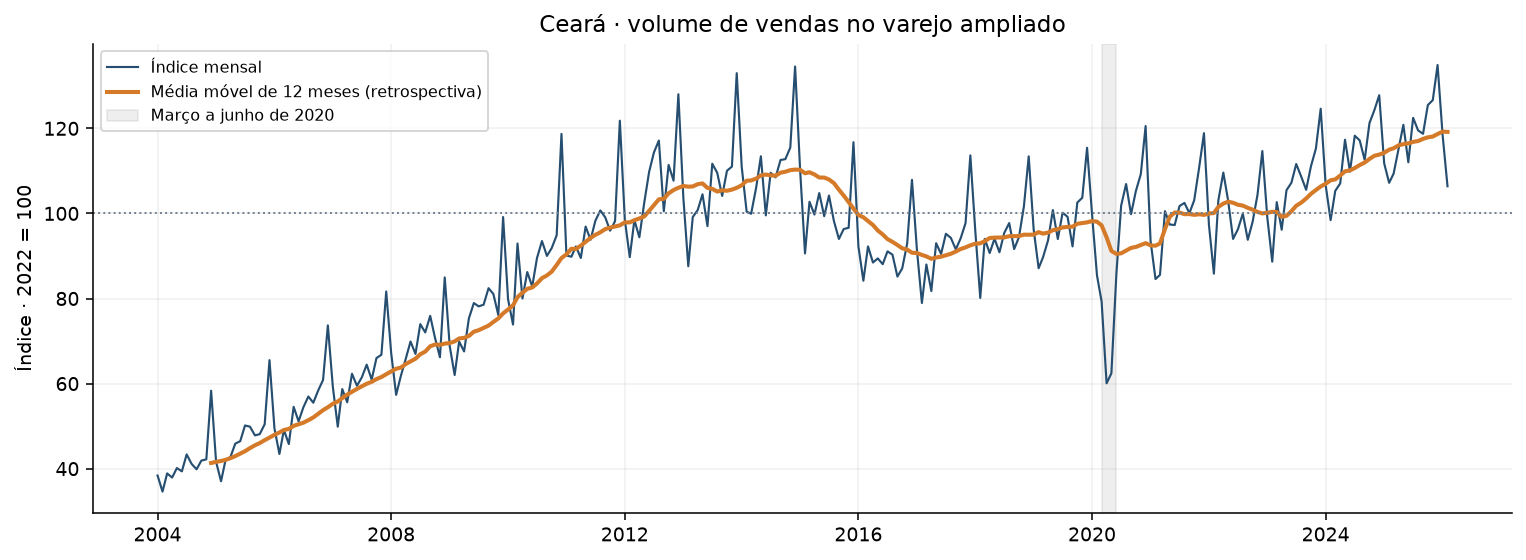

In [2]:
#| label: descritiva
descricao = pd.DataFrame({
    "Estatística": ["Média", "Mediana", "Desvio-padrão", "Mínimo", "Máximo"],
    "Índice (2022 = 100)": [y.mean(), y.median(), y.std(ddof=1), y.min(), y.max()],
})
tabela(descricao)

fig, ax = plt.subplots(figsize=(11, 4.1))
ax.plot(y.index, y, linewidth=1.1, label="Índice mensal")
ax.plot(y.index, y.rolling(12).mean(), linewidth=2.1, color="#d57a28",
        label="Média móvel de 12 meses (retrospectiva)")
ax.axhline(100, color="#708090", linestyle=":", linewidth=1)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2020-06-01"),
           alpha=0.12, color="#777777", label="Março a junho de 2020")
ax.set(title="Ceará · volume de vendas no varejo ampliado", ylabel="Índice · 2022 = 100")
ax.legend(loc="upper left", fontsize=8)
figura(fig, "01_serie.png")

O gráfico mostra aumento do nível da série ao longo da amostra, mas esse movimento não é uniforme: há períodos de expansão, recuos e recuperação. A média móvel ajuda a separar essa trajetória das oscilações mensais. A queda em 2020 constitui uma ruptura visível; sua coincidência temporal com a pandemia não permite atribuir, apenas com este modelo univariado, toda a variação a uma causa específica.

Para comparar os meses sem confundir sazonalidade com o crescimento do nível, cada observação foi dividida pela média do respectivo ano. Usam-se somente anos completos nesse gráfico; portanto, janeiro e fevereiro de 2026 não entram nessa comparação. Os boxplots descrevem uma regularidade histórica, sem testar efeitos de calendário ou feriados.

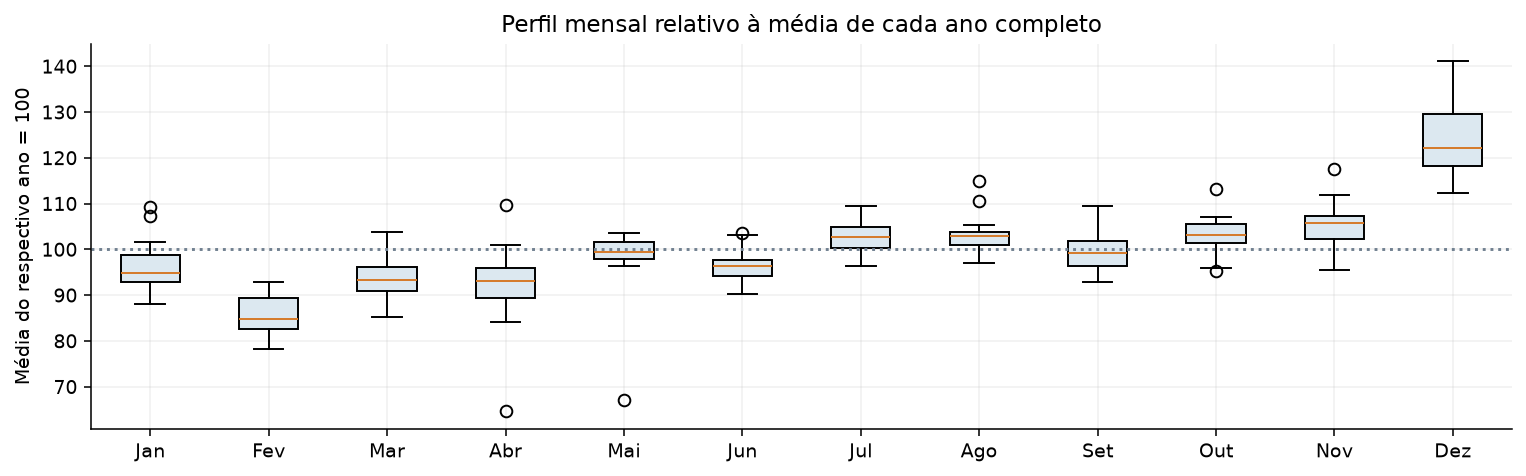

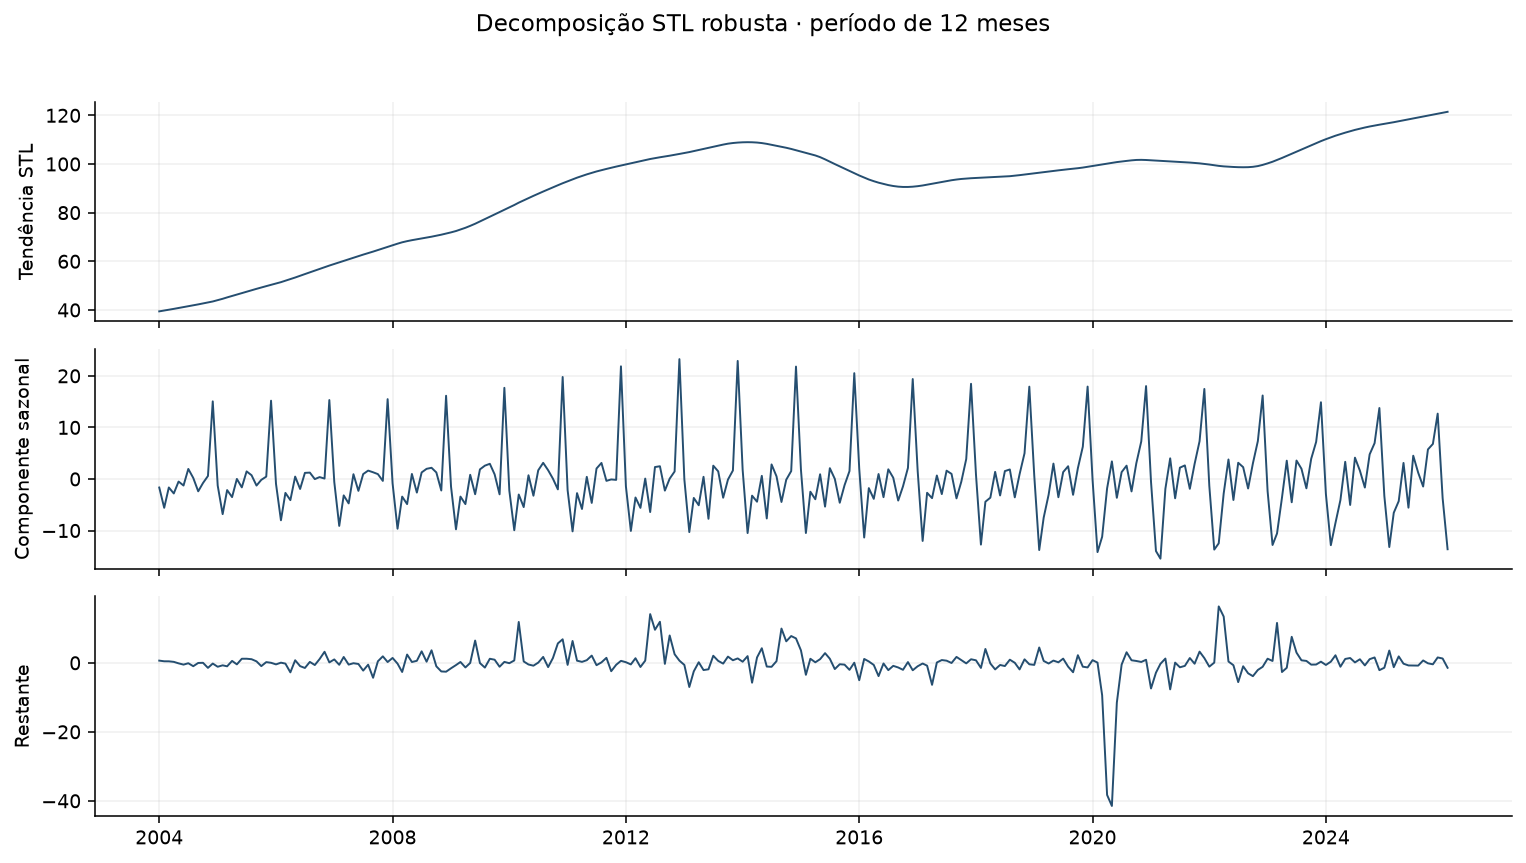

A decomposição STL apresenta força sazonal de **0,680** e força de tendência de **0,953**. Essas medidas descritivas são calculadas como $\max\{0, 1-\mathrm{Var}(R)/\mathrm{Var}(R+C)\}$, em que $C$ representa o componente avaliado. Não são p-valores nem testes de raiz unitária.

In [3]:
#| label: perfil-sazonal
anual = y.groupby(y.index.year).agg(["mean", "count"])
anos_completos = anual.index[anual["count"].eq(12)]
perfil = y.to_frame("indice")
perfil["ano"] = perfil.index.year
perfil["mes"] = perfil.index.month
perfil = perfil.loc[perfil["ano"].isin(anos_completos)].copy()
perfil["relativo"] = 100 * perfil["indice"] / perfil.groupby("ano")["indice"].transform("mean")
nomes_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.boxplot([perfil.loc[perfil["mes"].eq(m), "relativo"] for m in range(1, 13)],
           tick_labels=nomes_meses, patch_artist=True,
           boxprops={"facecolor": "#dce8f0"}, medianprops={"color": "#d57a28"})
ax.axhline(100, color="#708090", linestyle=":")
ax.set(title="Perfil mensal relativo à média de cada ano completo",
       ylabel="Média do respectivo ano = 100")
figura(fig, "02_perfil_mensal.png")

stl = STL(y, period=12, robust=True).fit()
forca_sazonal = max(0.0, 1 - np.var(stl.resid) / np.var(stl.resid + stl.seasonal))
forca_tendencia = max(0.0, 1 - np.var(stl.resid) / np.var(stl.resid + stl.trend))
fig, eixos = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, serie, titulo in zip(eixos, [stl.trend, stl.seasonal, stl.resid],
                             ["Tendência STL", "Componente sazonal", "Restante"]):
    ax.plot(y.index, serie, linewidth=1)
    ax.set_ylabel(titulo)
fig.suptitle("Decomposição STL robusta · período de 12 meses", y=1.02)
figura(fig, "03_stl.png")
display(Markdown(
    f"A decomposição STL apresenta força sazonal de **{br(forca_sazonal, 3)}** "
    f"e força de tendência de **{br(forca_tendencia, 3)}**. "
    "Essas medidas descritivas são calculadas como "
    r"$\max\{0, 1-\mathrm{Var}(R)/\mathrm{Var}(R+C)\}$, "
    "em que $C$ representa o componente avaliado. Não são p-valores nem testes de raiz unitária."
))

### ACF, PACF e diferenciação

A ACF mede correlação com defasagens da própria série; a PACF controla pelas defasagens intermediárias. Os limites desenhados são aproximações pontuais de 95%, úteis para exploração. Como a série em nível não é estacionária, sua interpretação deve ser combinada com as diferenças e com os testes seguintes.

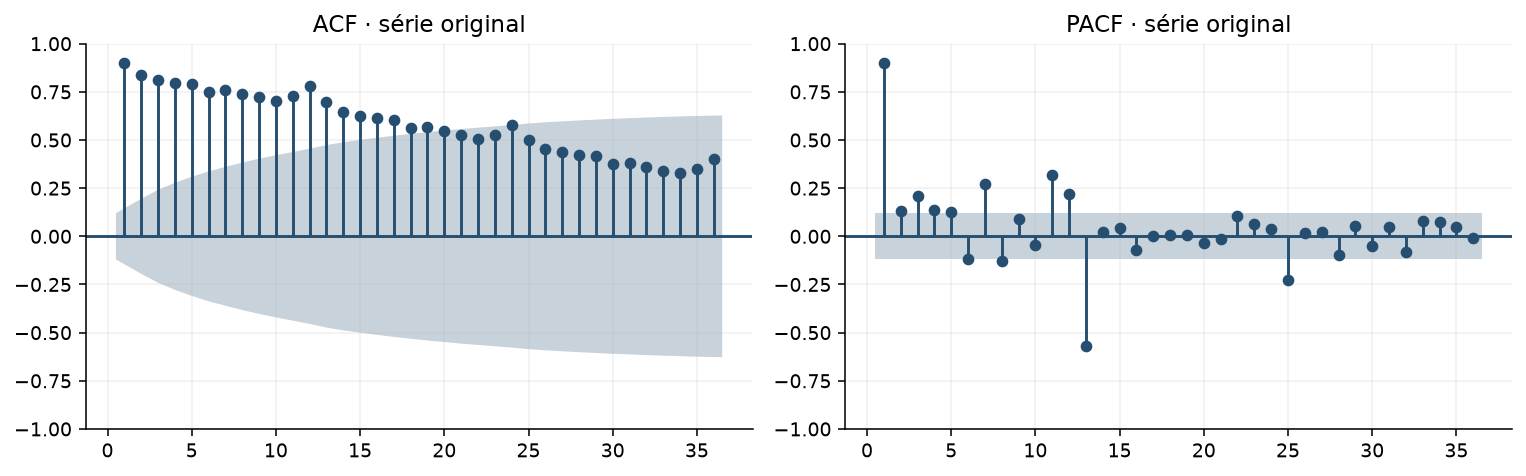

A ACF é **0,901** na defasagem 1, **0,782** em 12 e **0,576** em 24. O decaimento lento indica persistência, compatível com o movimento de longo prazo. A PACF em 12 é **0,220**. A repetição anual também aparece no perfil mensal e na STL; uma ACF elevada em 12, isoladamente, não distingue tendência de sazonalidade.

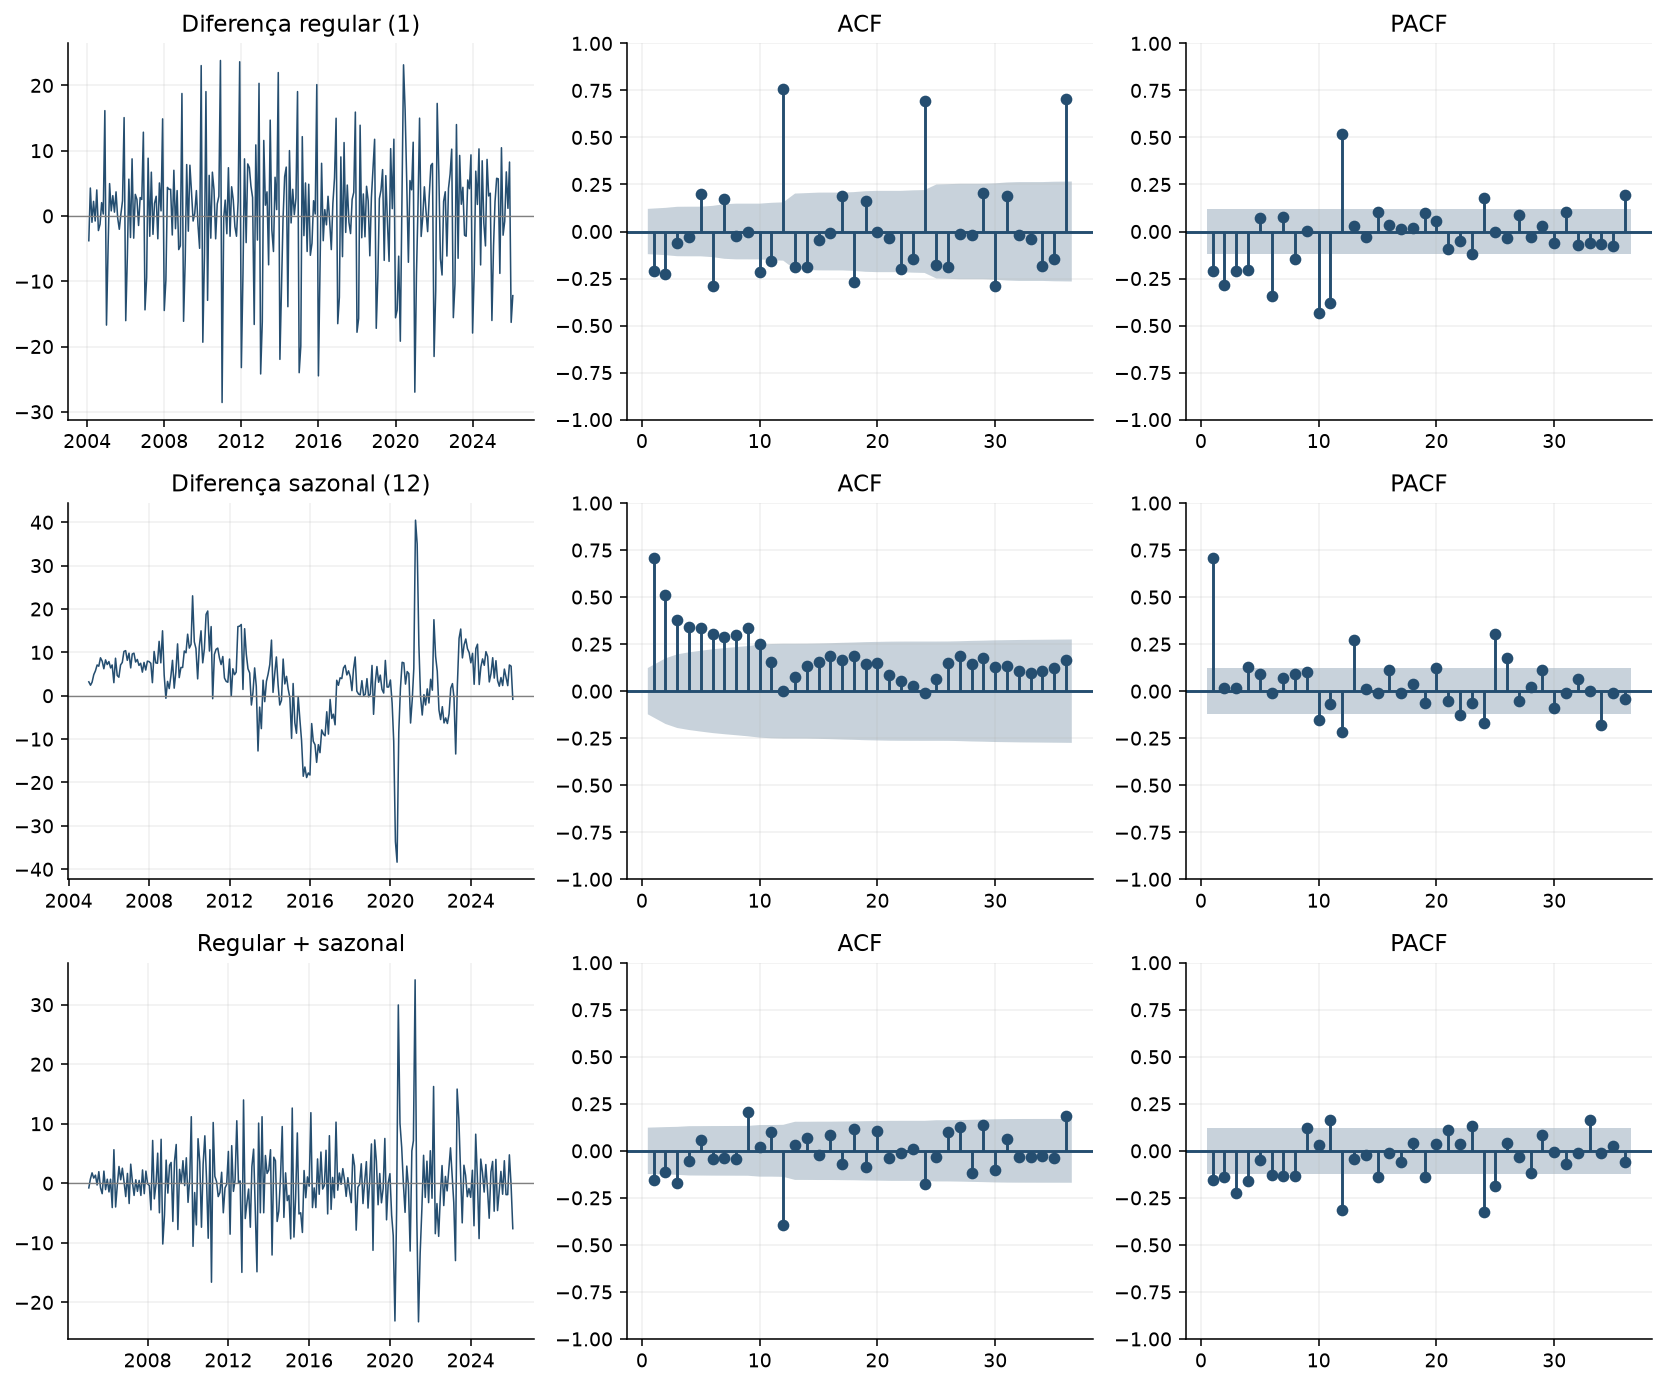

In [4]:
#| label: acf-nivel
fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5))
plot_acf(y, lags=36, zero=False, ax=eixos[0], title="ACF · série original")
plot_pacf(y, lags=36, zero=False, method="ywm", ax=eixos[1], title="PACF · série original")
figura(fig, "04_acf_pacf_original.png")
acf_original = acf(y, nlags=36)
pacf_original = pacf(y, nlags=36, method="ywm")
display(Markdown(
    f"A ACF é **{br(acf_original[1], 3)}** na defasagem 1, "
    f"**{br(acf_original[12], 3)}** em 12 e **{br(acf_original[24], 3)}** em 24. "
    "O decaimento lento indica persistência, compatível com o movimento de longo prazo. "
    f"A PACF em 12 é **{br(pacf_original[12], 3)}**. "
    "A repetição anual também aparece no perfil mensal e na STL; "
    "uma ACF elevada em 12, isoladamente, não distingue tendência de sazonalidade."
))

series = {
    "Nível": y,
    "Diferença regular (1)": y.diff().dropna(),
    "Diferença sazonal (12)": y.diff(12).dropna(),
    "Regular + sazonal": y.diff(12).diff().dropna(),
}
fig, eixos = plt.subplots(3, 3, figsize=(12, 10))
for linha, (nome, serie) in enumerate(list(series.items())[1:]):
    eixos[linha, 0].plot(serie.index, serie, linewidth=0.8)
    eixos[linha, 0].axhline(0, linewidth=0.7, color="gray")
    eixos[linha, 0].set_title(nome)
    plot_acf(serie, lags=36, zero=False, ax=eixos[linha, 1], title="ACF")
    plot_pacf(serie, lags=36, zero=False, method="ywm", ax=eixos[linha, 2], title="PACF")
figura(fig, "05_diferenciacao.png")

Aplicou-se a diferença regular $\Delta y_t = y_t-y_{t-1}$, a sazonal $\Delta_{12}y_t=y_t-y_{t-12}$ e a combinação $(1-B)(1-B^{12})y_t$. A diferença regular reduz a variação persistente do nível, mas pode deixar o ciclo anual. A sazonal compara cada mês com o mesmo mês do ano anterior. A combinação remove ambos os movimentos de forma mais clara nesta amostra, embora os choques não desapareçam. Não se exige que a série diferenciada seja ruído branco: as correlações restantes serão modeladas pelos termos AR e MA.

## Testes de raiz unitária e número de diferenças

No **ADF**, a hipótese nula é a presença de raiz unitária. No **KPSS**, a hipótese nula é estacionariedade em torno de uma constante. Adota-se significância de 5%. O ADF inclui constante e escolhe suas defasagens por AIC. No KPSS utiliza-se $\lfloor 3\sqrt{n}/13\rfloor$ defasagens, a mesma regra usada pelo `ndiffs` da versão instalada do StatsForecast, explicitada para permitir comparação.

Os valores de KPSS nos extremos da tabela são limites de interpolação: `≤0,01` e `≥0,10` não são probabilidades exatas. Testes em uma amostra com rupturas devem ser interpretados com os gráficos, sem tratar não rejeição como prova.

In [5]:
#| label: testes-estacionariedade
linhas = []
for nome, serie in series.items():
    adf = adfuller(serie, regression="c", autolag="AIC")
    lags_kpss = int(np.floor(3 * np.sqrt(len(serie)) / 13))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        kp = kpss(serie, regression="c", nlags=lags_kpss)
    p_kpss = "≤0,01" if kp[1] <= 0.01 else ("≥0,10" if kp[1] >= 0.1 else br(kp[1], 4))
    linhas.append({
        "Série": nome, "n": len(serie), "ADF": adf[0],
        "p ADF": f"{adf[1]:.3g}", "lags ADF": adf[2],
        "KPSS": kp[0], "p KPSS": p_kpss, "lags KPSS": kp[2],
        "ADF rejeita H0": "Sim" if adf[1] < 0.05 else "Não",
        "KPSS rejeita H0": "Sim" if kp[1] < 0.05 else "Não",
    })
testes = pd.DataFrame(linhas)
tabela(testes)
testes.to_csv(PASTA / "testes_estacionariedade.csv", index=False)

d_nivel = ndiffs(y.to_numpy(), test="kpss", alpha=0.05, max_d=2)
D_estimado = nsdiffs(y.to_numpy(), period=12, test="seas", max_D=1)
y_apos_sazonal = y.diff(12).dropna() if D_estimado else y
d_apos_sazonal = ndiffs(y_apos_sazonal.to_numpy(), test="kpss", alpha=0.05, max_d=2)
tabela(pd.DataFrame({
    "Procedimento": ["ndiffs no nível (KPSS)", "nsdiffs (força sazonal, seas)",
                     "ndiffs após a diferença sazonal"],
    "Diferenças estimadas": [d_nivel, D_estimado, d_apos_sazonal],
}))

| Série                  |   n |    ADF |   p ADF |   lags ADF |   KPSS | p KPSS   |   lags KPSS | ADF rejeita H0   | KPSS rejeita H0   |
|:-----------------------|----:|-------:|--------:|-----------:|-------:|:---------|------------:|:-----------------|:------------------|
| Nível                  | 266 | -2.107 |   0.242 |         12 |  4.353 | ≤0,01    |           3 | Não              | Sim               |
| Diferença regular (1)  | 265 | -5.751 |   0.000 |         11 |  0.049 | ≥0,10    |           3 | Sim              | Não               |
| Diferença sazonal (12) | 254 | -2.858 |   0.050 |         12 |  0.809 | ≤0,01    |           3 | Não              | Sim               |
| Regular + sazonal      | 253 | -6.288 |   0.000 |         11 |  0.013 | ≥0,10    |           3 | Sim              | Não               |

| Procedimento                    |   Diferenças estimadas |
|:--------------------------------|-----------------------:|
| ndiffs no nível (KPSS)          |                      1 |
| nsdiffs (força sazonal, seas)   |                      1 |
| ndiffs após a diferença sazonal |                      1 |

Em nível, o ADF não rejeita a raiz unitária e o KPSS rejeita a estacionariedade. Depois da diferença regular, os dois testes passam a ser compatíveis com estacionariedade segundo as especificações acima. Isso não elimina a necessidade de avaliar sazonalidade: o ADF usual não é um teste específico de raízes sazonais.

A diferença sazonal isolada deixa o ADF próximo do limite de 5% e o KPSS ainda rejeita estacionariedade. Com as duas diferenças, o ADF rejeita a raiz unitária e o KPSS não rejeita estacionariedade. O `ndiffs` sugere uma diferença regular, tanto no nível quanto após a diferença sazonal. O `nsdiffs(test="seas")` sugere uma sazonal; esse procedimento usa força sazonal, e não um teste formal de raiz unitária sazonal. Diferentes regras de defasagens podem mudar decisões marginais dos testes.

## Ajuste SARIMA via AutoARIMA

A série é modelada na escala original do índice, sem transformação logarítmica ou regressores externos. O procedimento `AutoARIMA(season_length=12)` seleciona diferenças e ordens por seus critérios automáticos. Utiliza-se o **AICc**, com busca *stepwise* e verossimilhança sem aproximação. A busca é heurística: o resultado não é garantia de mínimo global entre todas as especificações possíveis.

In [6]:
#| label: ajuste-autoarima
modelo = AutoARIMA(season_length=12)
modelo.fit(y.to_numpy())
ajuste = modelo.model_
# O vetor arma é armazenado na ordem p, q, P, Q, período, d, D.
p, q, P, Q, periodo, d, D = map(int, ajuste["arma"])
nome_modelo = f"SARIMA({p},{d},{q}) × ({P},{D},{Q})₁₂"
tabela(pd.DataFrame({
    "Medida": ["Modelo", "AIC", "AICc", "BIC", "Variância das inovações",
               "Código do otimizador"],
    "Resultado": [nome_modelo, br(ajuste["aic"], 3), br(ajuste["aicc"], 3),
                  br(ajuste["bic"], 3), br(ajuste["sigma2"], 3), int(ajuste["code"])],
}))
coeficientes = pd.DataFrame(ajuste["coef"].items(), columns=["Parâmetro", "Estimativa"])
tabela(coeficientes, 4)
coeficientes.to_csv(PASTA / "coeficientes.csv", index=False)
display(Markdown(
    f"O modelo escolhido foi **{nome_modelo}**: diferença regular **d={d}**, "
    f"diferença sazonal **D={D}**, componentes regulares **p={p}, q={q}** "
    f"e sazonais **P={P}, Q={Q}**. Não foi estimada constante ou drift. "
    "A ACF/PACF diferenciada ajuda a identificar dependência de curto prazo e anual, "
    "mas não oferece um corte visual inequívoco que determine todas essas ordens. "
    "Em modelos mistos, a seleção depende também do critério de informação e dos resíduos."
))

| Medida                  | Resultado                 |
|:------------------------|:--------------------------|
| Modelo                  | SARIMA(0,1,3) × (1,1,2)₁₂ |
| AIC                     | 1.533,651                 |
| AICc                    | 1.534,108                 |
| BIC                     | 1.558,384                 |
| Variância das inovações | 22,788                    |
| Código do otimizador    | 2                         |

| Parâmetro   |   Estimativa |
|:------------|-------------:|
| ma1         |      -0.3077 |
| ma2         |      -0.1582 |
| ma3         |      -0.1579 |
| sar1        |      -0.5600 |
| sma1        |      -0.1395 |
| sma2        |      -0.6474 |

O modelo escolhido foi **SARIMA(0,1,3) × (1,1,2)₁₂**: diferença regular **d=1**, diferença sazonal **D=1**, componentes regulares **p=0, q=3** e sazonais **P=1, Q=2**. Não foi estimada constante ou drift. A ACF/PACF diferenciada ajuda a identificar dependência de curto prazo e anual, mas não oferece um corte visual inequívoco que determine todas essas ordens. Em modelos mistos, a seleção depende também do critério de informação e dos resíduos.

Para essa especificação, a equação, na convenção dos coeficientes estimados, é:

$$
(1-\Phi_1 B^{12})(1-B)(1-B^{12})y_t
= (1+\theta_1B+\theta_2B^2+\theta_3B^3)
  (1+\Theta_1B^{12}+\Theta_2B^{24})\varepsilon_t.
$$

### Verificação numérica do ajuste

Um critério de informação baixo não substitui a verificação da otimização. O código retornado pelo AutoARIMA é registrado acima. Como o ajuste apresentou código 2, associado a perda de precisão do otimizador, estimou-se a **mesma estrutura** em uma implementação independente (`SARIMAX`, Statsmodels). Essa checagem não altera a seleção de ordens nem substitui as previsões exigidas do AutoARIMA.

In [7]:
#| label: verificacao-numerica
checagem = SARIMAX(y, order=(p, d, q), seasonal_order=(P, D, Q, 12), trend="n")
checagem = checagem.fit(disp=False, maxiter=1000)
convergiu_checagem = bool(checagem.mle_retvals.get("converged", False))
prev_auto = np.asarray(modelo.predict(h=HORIZONTE)["mean"])
prev_checagem = np.asarray(checagem.forecast(HORIZONTE))
desvio_checagem = float(np.max(np.abs(prev_auto - prev_checagem)))
display(Markdown(
    f"A implementação independente **{'convergiu' if convergiu_checagem else 'não convergiu'}**. "
    f"A maior diferença entre as previsões pontuais dos dois ajustes, no horizonte de 24 meses, "
    f"foi de **{br(desvio_checagem, 3)} ponto do índice**. "
    "A proximidade é uma evidência de estabilidade das previsões pontuais nesta amostra; "
    "não elimina o aviso numérico nem comprova a calibração dos intervalos."
))

A implementação independente **convergiu**. A maior diferença entre as previsões pontuais dos dois ajustes, no horizonte de 24 meses, foi de **0,377 ponto do índice**. A proximidade é uma evidência de estabilidade das previsões pontuais nesta amostra; não elimina o aviso numérico nem comprova a calibração dos intervalos.

## Diagnóstico dos resíduos

Os resíduos são as inovações estimadas pelo modelo. Retiram-se as primeiras `max(12, d + 12D)` observações, por precaução com a inicialização e a diferenciação. Avaliam-se média, ACF, distribuição e dependência temporal. No Ljung–Box, os graus de liberdade são ajustados por $p+q+P+Q$, sem contar diferenças como parâmetros AR/MA.

|   Defasagem |   lb_stat |   lb_pvalue |
|------------:|----------:|------------:|
|      12.000 |     8.905 |       0.179 |
|      24.000 |    13.865 |       0.738 |
|      36.000 |    26.898 |       0.629 |

| Diagnóstico               |   Estatística | p-valor   |
|:--------------------------|--------------:|:----------|
| Média dos resíduos        |        -0.194 | —         |
| Desvio-padrão             |         4.722 | —         |
| Jarque–Bera (normalidade) |       143.311 | 7.59e-32  |
| ARCH-LM (12 defasagens)   |        51.659 | 7.13e-07  |

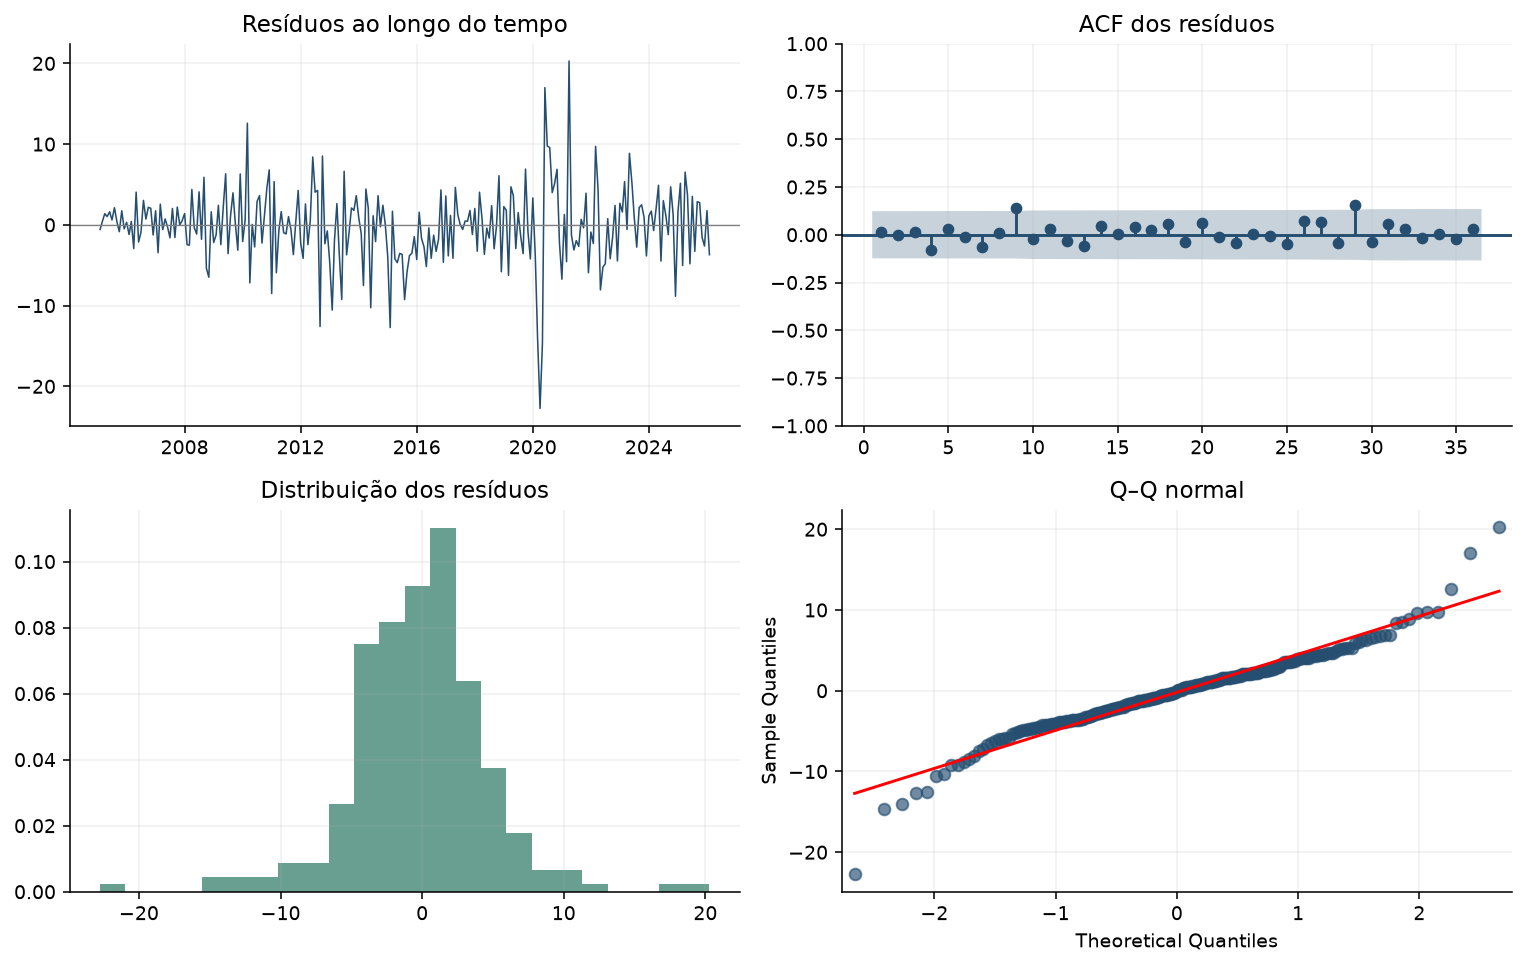

In [8]:
#| label: diagnostico-residuos
inicio_residuos = max(12, d + 12 * D)
residuos = pd.Series(np.asarray(ajuste["residuals"]), index=y.index).iloc[inicio_residuos:]
assert np.isfinite(residuos).all()
graus_modelo = p + q + P + Q
ljung = acorr_ljungbox(residuos, lags=[12, 24, 36], model_df=graus_modelo)
ljung.index.name = "Defasagem"
tabela(ljung.reset_index())
ljung.to_csv(PASTA / "ljung_box.csv")
jb = jarque_bera(residuos)
arch = het_arch(residuos, nlags=12, ddof=graus_modelo)
tabela(pd.DataFrame({
    "Diagnóstico": ["Média dos resíduos", "Desvio-padrão", "Jarque–Bera (normalidade)",
                    "ARCH-LM (12 defasagens)"],
    "Estatística": [residuos.mean(), residuos.std(ddof=1), jb.statistic, arch[0]],
    "p-valor": ["—", "—", f"{jb.pvalue:.3g}", f"{arch[1]:.3g}"],
}))

fig, eixos = plt.subplots(2, 2, figsize=(11, 7))
eixos[0, 0].plot(residuos.index, residuos, linewidth=0.8)
eixos[0, 0].axhline(0, color="gray", linewidth=0.7)
eixos[0, 0].set_title("Resíduos ao longo do tempo")
plot_acf(residuos, lags=36, zero=False, ax=eixos[0, 1], title="ACF dos resíduos")
eixos[1, 0].hist(residuos, bins=24, density=True, alpha=0.8, color="#438776")
eixos[1, 0].set_title("Distribuição dos resíduos")
qqplot(residuos, line="s", ax=eixos[1, 1], markerfacecolor="#254e70", alpha=0.65)
eixos[1, 1].set_title("Q–Q normal")
figura(fig, "06_residuos.png")

In [9]:
#| label: interpretacao-residuos
display(Markdown(
    f"Após retirar **{inicio_residuos}** observações iniciais, a média dos resíduos é "
    f"**{br(residuos.mean(), 3)}**. Os p-valores do Ljung–Box são "
    + ", ".join(f"**{br(ljung.loc[k, 'lb_pvalue'], 3)}** em {k}" for k in [12, 24, 36])
    + " defasagens. Não se rejeita ausência conjunta de autocorrelação nesses horizontes, "
    "sem evidência forte de padrão linear sazonal remanescente. "
    f"Já o Jarque–Bera (p={jb.pvalue:.2g}) rejeita normalidade e o ARCH-LM "
    f"(p={arch[1]:.2g}) indica dependência na variância. Portanto, os resíduos são "
    "compatíveis com ausência de autocorrelação linear, mas não com ruído branco "
    "gaussiano de variância constante. Os intervalos normais do SARIMA precisam "
    "ser lidos como aproximações condicionais ao modelo."
))

Após retirar **13** observações iniciais, a média dos resíduos é **-0,194**. Os p-valores do Ljung–Box são **0,179** em 12, **0,738** em 24, **0,629** em 36 defasagens. Não se rejeita ausência conjunta de autocorrelação nesses horizontes, sem evidência forte de padrão linear sazonal remanescente. Já o Jarque–Bera (p=7.6e-32) rejeita normalidade e o ARCH-LM (p=7.1e-07) indica dependência na variância. Portanto, os resíduos são compatíveis com ausência de autocorrelação linear, mas não com ruído branco gaussiano de variância constante. Os intervalos normais do SARIMA precisam ser lidos como aproximações condicionais ao modelo.

## Validação temporal complementar

Além do diagnóstico dentro da amostra, reservam-se os últimos **24 meses observados** para uma avaliação fora da amostra. Ajusta-se outro AutoARIMA somente ao período anterior ao teste. Compara-se com o **ingênuo sazonal**, que repete os 12 meses finais do treinamento. Não se utilizam observações do teste para selecionar as ordens desse ajuste.

Essa é uma única janela de avaliação, e não validação com múltiplas origens. Como a base do exercício pode conter revisões históricas, trata-se de avaliação retrospectiva com a versão disponível, sem reconstruir as versões divulgadas em cada época.

| Modelo          |   MAE (pontos) |   RMSE (pontos) |   MAPE (%) |
|:----------------|---------------:|----------------:|-----------:|
| AutoARIMA       |          5.624 |           6.400 |      4.757 |
| Ingênuo sazonal |          9.293 |          10.118 |      7.891 |

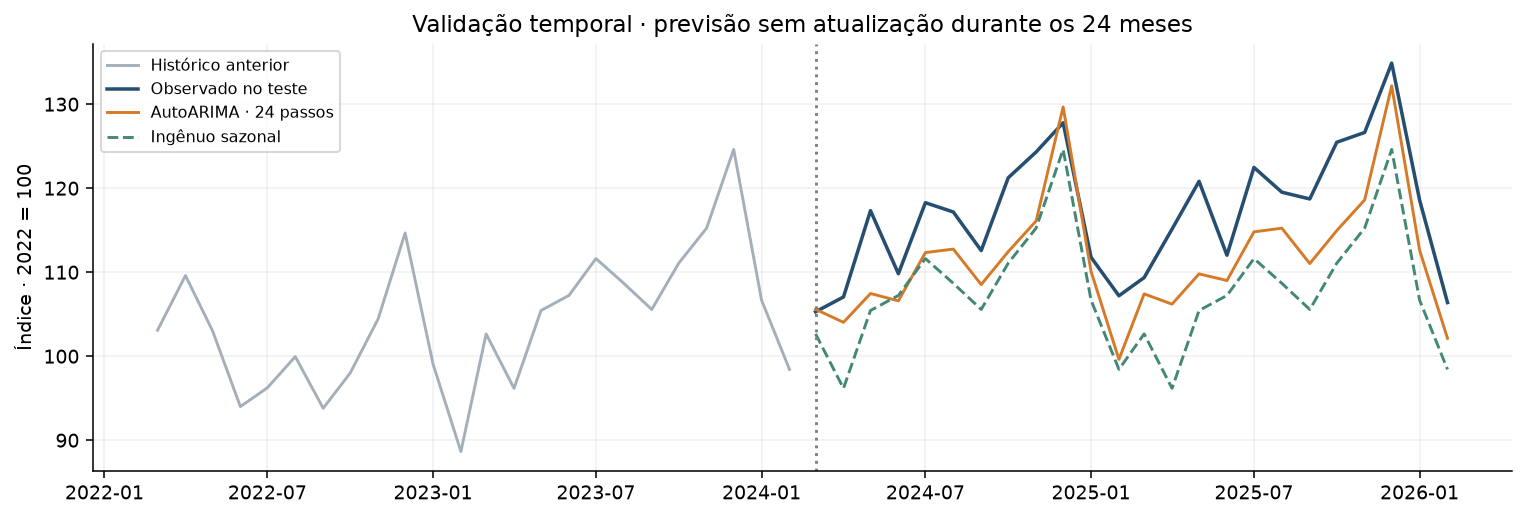

O treinamento termina em **02/2024** e o teste cobre **03/2024 a 02/2026**. O menor RMSE nesta janela foi o do **AutoARIMA**. As coberturas observadas dos intervalos do AutoARIMA foram **95,8%** para o nível nominal de 80% e **100,0%** para o de 95%. Com apenas 24 erros, essas frequências não bastam para concluir que os intervalos estejam bem calibrados em outros períodos. A especificação do treinamento pode diferir da selecionada na amostra completa.

In [10]:
#| label: validacao
treino, teste = y.iloc[:-HORIZONTE], y.iloc[-HORIZONTE:]
modelo_treino = AutoARIMA(season_length=12).fit(treino.to_numpy())
previsao_teste = modelo_treino.predict(h=HORIZONTE, level=[80, 95])
ingenuo = np.tile(treino.iloc[-12:].to_numpy(), 2)
linhas_metricas = []
for nome, pred in [("AutoARIMA", np.asarray(previsao_teste["mean"])),
                   ("Ingênuo sazonal", ingenuo)]:
    erro = teste.to_numpy() - pred
    linhas_metricas.append({
        "Modelo": nome, "MAE (pontos)": np.mean(np.abs(erro)),
        "RMSE (pontos)": np.sqrt(np.mean(erro**2)),
        "MAPE (%)": np.mean(np.abs(erro / teste.to_numpy())) * 100,
    })
metricas = pd.DataFrame(linhas_metricas)
tabela(metricas)
metricas.to_csv(PASTA / "metricas_validacao.csv", index=False)
coberturas = {}
for nivel in [80, 95]:
    baixo = np.asarray(previsao_teste[f"lo-{nivel}"])
    alto = np.asarray(previsao_teste[f"hi-{nivel}"])
    coberturas[nivel] = float(np.mean((teste.to_numpy() >= baixo) & (teste.to_numpy() <= alto)))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(treino.iloc[-24:].index, treino.iloc[-24:], color="#a5afba", label="Histórico anterior")
ax.plot(teste.index, teste, color="#254e70", linewidth=1.8, label="Observado no teste")
ax.plot(teste.index, previsao_teste["mean"], color="#d57a28", label="AutoARIMA · 24 passos")
ax.plot(teste.index, ingenuo, color="#438776", linestyle="--", label="Ingênuo sazonal")
ax.axvline(teste.index[0], color="gray", linestyle=":")
ax.set(title="Validação temporal · previsão sem atualização durante os 24 meses",
       ylabel="Índice · 2022 = 100")
ax.legend(fontsize=8)
figura(fig, "07_validacao.png")
melhor = metricas.loc[metricas["RMSE (pontos)"].idxmin(), "Modelo"]
display(Markdown(
    f"O treinamento termina em **{mes(treino.index[-1])}** e o teste cobre "
    f"**{mes(teste.index[0])} a {mes(teste.index[-1])}**. "
    f"O menor RMSE nesta janela foi o do **{melhor}**. "
    f"As coberturas observadas dos intervalos do AutoARIMA foram "
    f"**{br(100*coberturas[80], 1)}%** para o nível nominal de 80% e "
    f"**{br(100*coberturas[95], 1)}%** para o de 95%. "
    "Com apenas 24 erros, essas frequências não bastam para concluir que os intervalos "
    "estejam bem calibrados em outros períodos. A especificação do treinamento pode "
    "diferir da selecionada na amostra completa."
))

## Previsão de 24 meses

Para a previsão final, utiliza-se o AutoARIMA ajustado aos 266 meses, incluindo o período reservado apenas na validação complementar. Os intervalos de 80% e 95% são **intervalos de previsão para observações futuras**, sob as hipóteses do modelo; não são intervalos para uma média histórica nem garantias de realização.

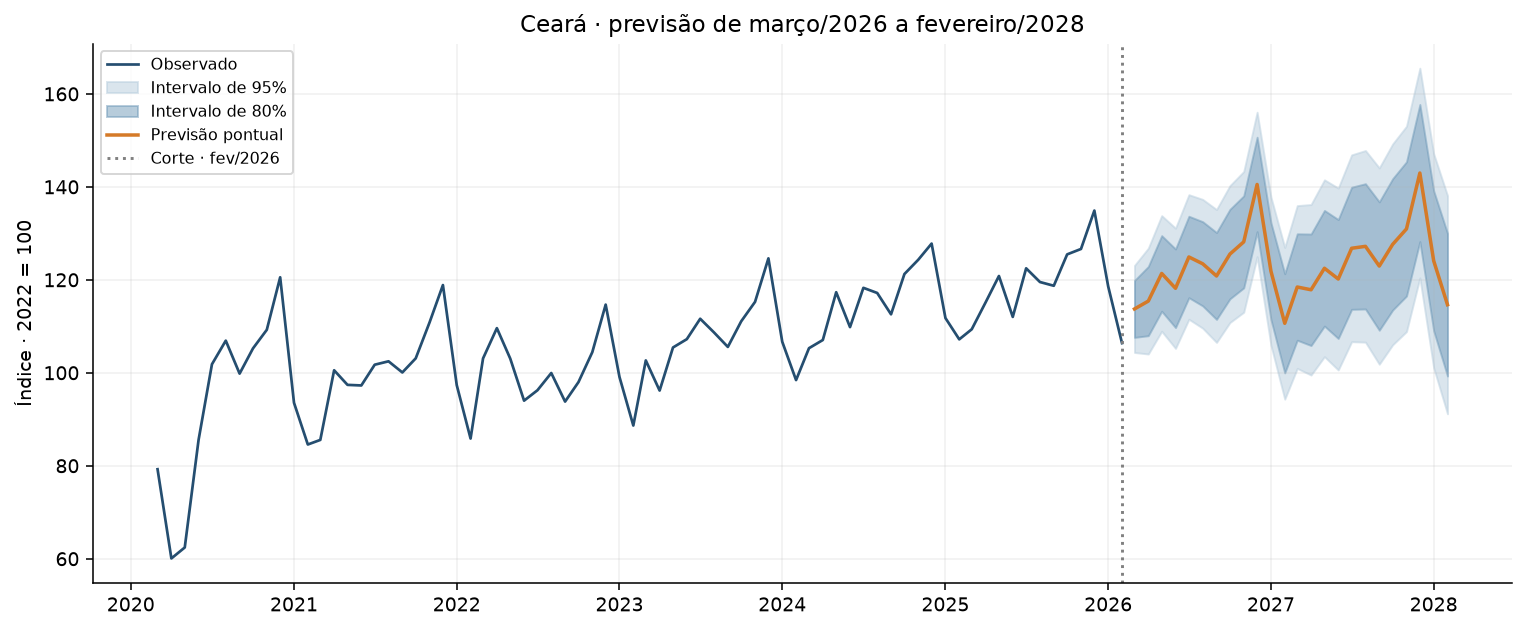

| Mês     |   Previsão |   LI 80% |   LS 80% |   LI 95% |   LS 95% |
|:--------|-----------:|---------:|---------:|---------:|---------:|
| 03/2026 |     113.73 |   107.61 |   119.85 |   104.37 |   123.09 |
| 04/2026 |     115.42 |   107.98 |   122.87 |   104.04 |   126.81 |
| 05/2026 |     121.37 |   113.24 |   129.50 |   108.93 |   133.80 |
| 06/2026 |     118.17 |   109.72 |   126.62 |   105.25 |   131.10 |
| 07/2026 |     124.91 |   116.15 |   133.67 |   111.52 |   138.31 |
| 08/2026 |     123.44 |   114.39 |   132.50 |   109.60 |   137.29 |
| 09/2026 |     120.82 |   111.48 |   130.17 |   106.53 |   135.11 |
| 10/2026 |     125.53 |   115.91 |   135.15 |   110.81 |   140.25 |
| 11/2026 |     128.16 |   118.26 |   138.06 |   113.03 |   143.29 |
| 12/2026 |     140.51 |   130.35 |   150.67 |   124.98 |   156.05 |
| 01/2027 |     121.87 |   111.45 |   132.28 |   105.93 |   137.80 |
| 02/2027 |     110.64 |    99.97 |   121.31 |    94.32 |   126.96 |
| 03/2027 |     118.45 |   107.01 |   129.90 |   100.95 |   135.96 |
| 04/2027 |     117.86 |   105.86 |   129.85 |    99.51 |   136.20 |
| 05/2027 |     122.49 |   110.05 |   134.92 |   103.47 |   141.50 |
| 06/2027 |     120.17 |   107.38 |   132.96 |   100.61 |   139.73 |
| 07/2027 |     126.78 |   113.65 |   139.92 |   106.69 |   146.88 |
| 08/2027 |     127.20 |   113.72 |   140.67 |   106.59 |   147.81 |
| 09/2027 |     122.96 |   109.15 |   136.76 |   101.84 |   144.07 |
| 10/2027 |     127.62 |   113.50 |   141.75 |   106.02 |   149.23 |
| 11/2027 |     130.95 |   116.51 |   145.39 |   108.87 |   153.03 |
| 12/2027 |     142.97 |   128.22 |   157.72 |   120.42 |   165.53 |
| 01/2028 |     124.09 |   109.05 |   139.14 |   101.08 |   147.11 |
| 02/2028 |     114.64 |    99.29 |   129.98 |    91.17 |   138.10 |

In [11]:
#| label: previsoes
saida = modelo.predict(h=HORIZONTE, level=[80, 95])
datas_futuras = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1),
                            periods=HORIZONTE, freq="MS")
previsoes = pd.DataFrame({
    "data": datas_futuras, "previsao": np.asarray(saida["mean"]),
    "inferior_80": np.asarray(saida["lo-80"]),
    "superior_80": np.asarray(saida["hi-80"]),
    "inferior_95": np.asarray(saida["lo-95"]),
    "superior_95": np.asarray(saida["hi-95"]),
})
assert len(previsoes) == 24 and np.isfinite(previsoes.iloc[:, 1:].to_numpy()).all()
assert (previsoes["inferior_95"] <= previsoes["inferior_80"]).all()
assert (previsoes["inferior_80"] <= previsoes["previsao"]).all()
assert (previsoes["previsao"] <= previsoes["superior_80"]).all()
assert (previsoes["superior_80"] <= previsoes["superior_95"]).all()
previsoes.to_csv(PASTA / "previsoes_24_meses.csv", index=False, date_format="%Y-%m-%d")

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(y.iloc[-72:].index, y.iloc[-72:], label="Observado", linewidth=1.4)
ax.fill_between(datas_futuras, previsoes["inferior_95"], previsoes["superior_95"],
                color="#b7cddd", alpha=0.5, label="Intervalo de 95%")
ax.fill_between(datas_futuras, previsoes["inferior_80"], previsoes["superior_80"],
                color="#6995b5", alpha=0.48, label="Intervalo de 80%")
ax.plot(datas_futuras, previsoes["previsao"], color="#d57a28", linewidth=1.8,
        label="Previsão pontual")
ax.axvline(y.index[-1], color="gray", linestyle=":", label="Corte · fev/2026")
ax.set(title="Ceará · previsão de março/2026 a fevereiro/2028",
       ylabel="Índice · 2022 = 100")
ax.legend(loc="upper left", fontsize=8)
figura(fig, "08_previsao.png")

quadro_previsoes = previsoes.copy()
quadro_previsoes["data"] = quadro_previsoes["data"].dt.strftime("%m/%Y")
quadro_previsoes.columns = ["Mês", "Previsão", "LI 80%", "LS 80%", "LI 95%", "LS 95%"]
tabela(quadro_previsoes, 2)

In [12]:
#| label: interpretacao-previsoes
primeira, ultima = previsoes.iloc[0], previsoes.iloc[-1]
largura_inicio = primeira["superior_95"] - primeira["inferior_95"]
largura_fim = ultima["superior_95"] - ultima["inferior_95"]
dezembro_2026 = previsoes.loc[previsoes["data"].eq("2026-12-01"), "previsao"].iloc[0]
dezembro_2027 = previsoes.loc[previsoes["data"].eq("2027-12-01"), "previsao"].iloc[0]
display(Markdown(
    f"A projeção começa em **{br(primeira['previsao'])}** para março de 2026. "
    f"Mantém picos de fim de ano, com **{br(dezembro_2026)}** em dezembro de 2026 "
    f"e **{br(dezembro_2027)}** em dezembro de 2027. Fevereiro de 2028 termina "
    f"em **{br(ultima['previsao'])}**, com intervalo de 95% de "
    f"**{br(ultima['inferior_95'])} a {br(ultima['superior_95'])}**. "
    f"A largura do intervalo de 95% cresce de **{br(largura_inicio)}** para "
    f"**{br(largura_fim)} pontos** entre o primeiro e o último horizonte. "
    "Esse alargamento representa a acumulação de incerteza. A trajetória prolonga "
    "padrões do histórico; choques econômicos, mudanças de comportamento e revisões "
    "da pesquisa não estão explicitamente modelados."
))

A projeção começa em **113,73** para março de 2026. Mantém picos de fim de ano, com **140,51** em dezembro de 2026 e **142,97** em dezembro de 2027. Fevereiro de 2028 termina em **114,64**, com intervalo de 95% de **91,17 a 138,10**. A largura do intervalo de 95% cresce de **18,72** para **46,93 pontos** entre o primeiro e o último horizonte. Esse alargamento representa a acumulação de incerteza. A trajetória prolonga padrões do histórico; choques econômicos, mudanças de comportamento e revisões da pesquisa não estão explicitamente modelados.

## Discussão: respostas às perguntas do exercício

**1. A ACF/PACF sugeriu sazonalidade e tendência?** Sim. A ACF em nível é elevada e decai lentamente, coerente com a mudança de nível no gráfico de linha. A dependência anual, o perfil dos meses e a STL sustentam a presença de sazonalidade de 12 meses. A tendência contamina a ACF original; por isso, as diferenças são necessárias para uma leitura mais útil dos componentes AR/MA.

**2. Quantas diferenças e quais componentes foram selecionados?** O AutoARIMA escolheu uma diferença regular e uma sazonal: $d=1$ e $D=1$. A estrutura é SARIMA$(0,1,3)\times(1,1,2)_{12}$, com três termos MA regulares, um AR sazonal e dois MA sazonais. As ACF/PACF diferenciadas são compatíveis com dependência curta e anual, mas não permitem deduzir com segurança todas essas ordens apenas visualmente.

**3. Os resíduos parecem ruído branco?** O Ljung–Box não rejeita ausência de autocorrelação em 12, 24 e 36 meses, de modo que não ficou um padrão linear sazonal forte. Entretanto, os resíduos apresentam caudas incompatíveis com normalidade e indícios de variância condicional variável. Assim, seria impreciso classificá-los como ruído branco gaussiano; o diagnóstico favorece a dinâmica da média, com ressalvas para a distribuição e os intervalos.

**4. A previsão é visualmente razoável?** Ela continua próxima do nível recente, reproduz a elevação de fim de ano e apresenta intervalos progressivamente mais largos. Essas características são coerentes com a série, mas não bastam para validar sua precisão. A comparação fora da amostra, a ressalva sobre heterocedasticidade e o aviso do otimizador limitam a confiança que se deve atribuir à extrapolação.

**5. Quais UFs poderiam resultar em um SARIMA diferente?** Amazonas e São Paulo seriam comparações interessantes com o Ceará. Como hipótese a investigar, diferenças na composição das vendas, no peso de veículos e material de construção e no calendário de consumo podem alterar persistência e intensidade sazonal. Essa é uma proposta de comparação, não um resultado estimado: seria necessário repetir os mesmos procedimentos para cada UF antes de afirmar quais ordens mudariam.

## Conclusão

O varejo ampliado do Ceará apresenta trajetória de longo prazo e um ciclo anual que justificam a modelagem sazonal. Uma diferença regular e uma sazonal tornam a série mais compatível com estacionariedade, enquanto os termos AR/MA capturam dependências restantes. O modelo selecionado descreve a sazonalidade e gera uma trajetória de previsão coerente com o histórico observado.

A ausência de autocorrelação residual relevante não resolve todos os problemas do ajuste. A não normalidade, a variância variável e o aviso numérico exigem cautela, principalmente ao interpretar probabilidades dos intervalos. A convergência de uma implementação independente e a proximidade de suas previsões pontuais ajudam a verificar a estabilidade numérica, mas não substituem validação em outras janelas. Uma extensão útil seria repetir a avaliação com origens móveis e examinar o efeito de choques e mudanças de regime.

## Reprodutibilidade e referências

Para executar novamente, instale `uv` e o Quarto, abra esta pasta e rode:

```{.bash}
uv sync --frozen
uv run quarto render template-exercicio-sarima.qmd --to html
```

O comando produz `index.html` com recursos incorporados. A configuração do ambiente e os dados utilizados acompanham o projeto; a pasta `.venv` não deve ser enviada ao GitHub. As tabelas e as figuras são recalculadas e gravadas em `resultados/` durante a execução.

In [13]:
#| label: registro-execucao
versoes = {pacote: version(pacote) for pacote in
           ["numpy", "pandas", "matplotlib", "scipy", "statsmodels", "statsforecast"]}
registro = {
    "uf": MINHA_UF, "inicio": str(y.index[0].date()), "fim": str(y.index[-1].date()),
    "n": len(y), "fonte": FONTE, "sha256_base": sha256,
    "modelo": nome_modelo, "arma": list(map(int, ajuste["arma"])),
    "codigo_otimizador": int(ajuste["code"]), "aicc": float(ajuste["aicc"]),
    "checagem_statsmodels_convergiu": convergiu_checagem,
    "desvio_maximo_previsao_checagem": desvio_checagem,
    "ljung_box_p": {str(k): float(v) for k, v in ljung["lb_pvalue"].items()},
    "jarque_bera_p": float(jb.pvalue), "arch_lm_p": float(arch[1]),
    "ndiffs_nivel": int(d_nivel), "nsdiffs": int(D_estimado),
    "ndiffs_apos_sazonal": int(d_apos_sazonal),
    "cobertura_validacao": {str(k): v for k, v in coberturas.items()},
    "python": platform.python_version(), "versoes": versoes,
}
(PASTA / "registro_execucao.json").write_text(
    json.dumps(registro, ensure_ascii=False, indent=2), encoding="utf-8")
tabela(pd.DataFrame(versoes.items(), columns=["Pacote", "Versão"]))
display(Markdown(f"**SHA-256 do arquivo de entrada:** `{sha256}`"))

| Pacote        | Versão   |
|:--------------|:---------|
| numpy         | 2.5.4    |
| pandas        | 2.3.3    |
| matplotlib    | 3.11.2   |
| scipy         | 1.18.1   |
| statsmodels   | 0.14.6   |
| statsforecast | 2.1.1    |

**SHA-256 do arquivo de entrada:** `bfc7977540940ccbdaf252646d5c5025fd2eca02f2eee50fb45564706e5e7d64`

- [Template e enunciado da disciplina](https://github.com/padsInsper/202634-fa/blob/main/dinamicas/template-exercicio-sarima.qmd).
- [Base pré-processada disponibilizada pelo professor](https://github.com/padsInsper/202634-fa/releases/download/data/pmc_volume_uf.csv), copiada em 28/10/2026.
- [IBGE — Pesquisa Mensal de Comércio](https://www.ibge.gov.br/estatisticas/economicas/comercio/9227-pesquisa-mensal-de-comercio.html).
- [IBGE — SIDRA, tabela 8881: comércio varejista ampliado, referência 2022 = 100](https://sidra.ibge.gov.br/tabela/8881).
- [StatsForecast — implementação e documentação do AutoARIMA](https://github.com/Nixtla/statsforecast).
- [Statsmodels — ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html), [KPSS](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html) e [Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html).